<a href="https://colab.research.google.com/github/mlvrnaaaa/ucs-drone-pengiriman-obat/blob/main/ucs_drone_pengiriman_obat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TABEL LANGKAH PENCARIAN UCS


,Langkah,Ekspansi,Frontier,Keterangan
0,0,-,PD=0,Mulai dari PD
1,1,PD,"A=4, B=7",Ekspansi selesai
2,2,A,"B=7, D=7, C=10, E=13",Ekspansi selesai
3,3,B,"D=7, C=10, E=11, F=13",E turun menjadi 11
4,4,D,"C=10, E=11, RS=12, F=13",Ekspansi selesai
5,5,C,"E=11, RS=12, F=13",Ekspansi selesai
6,6,E,"RS=12, F=13",Ekspansi selesai
7,7,RS,RS=12,Tujuan tercapai


Jalur optimal: PD -> A -> D -> RS
Total energi: 12 Wh


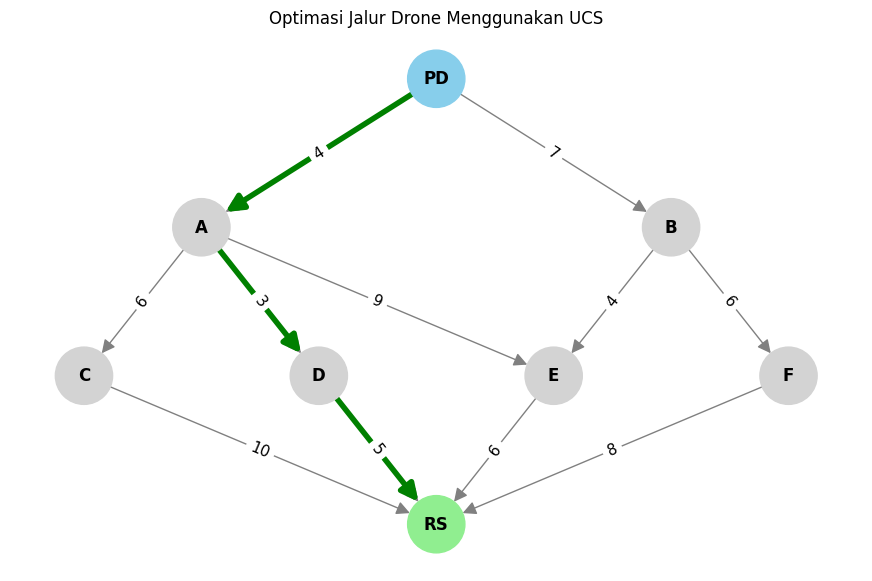

In [1]:

import heapq
import itertools
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

# Data graf: tujuan dan konsumsi energi (Wh)
graf = {
    'PD': [('A', 4), ('B', 7)],
    'A': [('C', 6), ('D', 3), ('E', 9)],
    'B': [('E', 4), ('F', 6)],
    'C': [('RS', 10)],
    'D': [('RS', 5)],
    'E': [('RS', 6)],
    'F': [('RS', 8)],
    'RS': []
}

def ucs(graf, awal, tujuan):
    urutan = itertools.count()
    frontier = [(0, next(urutan), awal, [awal])]
    terbaik = {awal: 0}
    tabel = [[0, "-", "PD=0", "Mulai dari PD"]]
    langkah = 0

    while frontier:
        cost, _, node, jalur = heapq.heappop(frontier)

        # Abaikan entri lama yang sudah diperbaiki
        if cost > terbaik[node]:
            continue

        langkah += 1

        if node == tujuan:
            tabel.append([
                langkah, node, f"{node}={cost}",
                "Tujuan tercapai"
            ])
            return jalur, cost, tabel

        perubahan = []
        for tetangga, energi in graf[node]:
            baru = cost + energi
            lama = terbaik.get(tetangga, float("inf"))

            if baru < lama:
                terbaik[tetangga] = baru
                heapq.heappush(frontier, (
                    baru, next(urutan),
                    tetangga, jalur + [tetangga]
                ))
                if lama != float("inf"):
                    perubahan.append(
                        f"{tetangga} turun menjadi {baru}"
                    )

        aktif = sorted(frontier)
        daftar = [
            f"{n}={c}" for c, _, n, _ in aktif
            if c == terbaik[n]
        ]
        keterangan = "; ".join(perubahan) or "Ekspansi selesai"

        tabel.append([
            langkah, node,
            ", ".join(daftar),
            keterangan
        ])

    return None, None, tabel

# Jalankan UCS
jalur, cost, tabel = ucs(graf, "PD", "RS")

print("TABEL LANGKAH PENCARIAN UCS")
display(pd.DataFrame(
    tabel,
    columns=["Langkah", "Ekspansi",
             "Frontier", "Keterangan"]
))

print("Jalur optimal:", " -> ".join(jalur))
print("Total energi:", cost, "Wh")

# Visualisasi graf
G = nx.DiGraph()
for asal, daftar in graf.items():
    G.add_node(asal)
    for tujuan, energi in daftar:
        G.add_edge(asal, tujuan, weight=energi)

pos = {
    "PD": (0, 3),
    "A": (-2, 2),
    "B": (2, 2),
    "C": (-3, 1),
    "D": (-1, 1),
    "E": (1, 1),
    "F": (3, 1),
    "RS": (0, 0)
}

sisi_optimal = list(zip(jalur, jalur[1:]))

plt.figure(figsize=(11, 7))

nx.draw_networkx_nodes(
    G, pos, node_size=1700,
    node_color=[
        "lightgreen" if n == "RS"
        else "skyblue" if n == "PD"
        else "lightgray" for n in G.nodes()
    ]
)
nx.draw_networkx_labels(G, pos, font_weight="bold")

nx.draw_networkx_edges(
    G, pos, edge_color="gray",
    arrows=True, arrowsize=20,
    node_size=1700
)
nx.draw_networkx_edges(
    G, pos, edgelist=sisi_optimal,
    edge_color="green", width=4,
    arrows=True, arrowsize=25,
    node_size=1700
)
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=nx.get_edge_attributes(G, "weight"),
    font_size=11
)

plt.title("Optimasi Jalur Drone Menggunakan UCS")
plt.axis("off")
plt.show()
